# Task 11, Notebook 03: Building and tuning the ranking engine

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 11: Rank resumes against job descriptions  
**Objective:** Preprocess, set baselines, build the TF-IDF + skills + experience engine, validate weights without tuning on the job being judged.  
**Workflow stages covered in this notebook:** 22, 23, 24, 25, 26, 27, 28, 29 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3 | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv
from cortexhr.phase3.resume import text as T
from cortexhr.phase3.common.validation import profile
resumes = read_csv('resumes'); jobs = read_csv('job_descriptions'); labels = read_csv('resume_job_labels'); pairs = read_csv('resume_bias_pairs')
dd = read_csv('data_dictionary')
print('resumes', resumes.shape, '| jobs', jobs.shape, '| labels', labels.shape, '| twin pairs', pairs.shape)

resumes (185, 15) | jobs (10, 11) | labels (555, 7) | twin pairs (25, 8)


In [3]:
from cortexhr.phase3.resume.scoring import ResumeRanker
from cortexhr.phase3.resume.metrics import attach_labels, evaluate, random_baseline
v1 = ResumeRanker(mask=False).fit(resumes, jobs)      # resume_text exactly as given
v2 = ResumeRanker(mask=True).fit(resumes, jobs)       # identifiers masked before scoring (final engine)
def score_labelled(r): return attach_labels(r.score_all(labels[['resume_id', 'job_id']]), labels)

## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Text preprocessing is fitted on resumes and jobs only (no labels). Identifiers are masked, skill phrases are kept as single tokens, plural folding is conservative.

In [4]:
r = resumes.iloc[4]; raw = r.resume_text[:300]
from cortexhr.phase3.resume import text as T
masked = T.mask_identifiers(r.resume_text, r.candidate_name, r.email, r.city)
print('RAW   :', raw.replace('\n', ' | ')); print('MASKED:', masked[:300].replace('\n', ' | ')); print('TOKENS:', T.tokenize(masked, v2.phrases)[:25])

RAW   : ISHA JOSEPH | Coimbatore | isha.joseph@mail-demo.example |  | SUMMARY | Motivated reporting analyst with 1.4 years of experience. Strengths include Critical Thinking, CRM, Statistics. |  | EXPERIENCE | Reporting Analyst, Orion Infotech (0.1 yrs) | - Automated weekly reports and saved 48 hours a month | - Built dashbo
MASKED:   |  |  |  | SUMMARY | Motivated reporting analyst with 1.4 years of experience. Strengths include Critical Thinking, CRM, Statistics. |  | EXPERIENCE | Reporting Analyst, Orion Infotech (0.1 yrs) | - Automated weekly reports and saved 48 hours a month | - Built dashboards used by 83 business users | Reporting Analyst,
TOKENS: ['summary', 'reporting', 'analyst', '1.4', 'strength', 'critical_thinking', 'crm', 'statistic', 'reporting', 'analyst', 'orion', 'infotech', '0.1', 'automated', 'weekly', 'report', 'saved', 'hour', 'month', 'built', 'dashboard', 'used', 'business', 'user', 'reporting']


## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

There is no supervised training in this engine, so there is no model to overfit to the labels. The labels are used **only to measure**. Weights were fixed a priori in the config (skills matter most, text similarity second, experience capped). Sensitivity and leave-one-job-out checks below test whether that choice was sensible.

In [5]:
print('weights fixed in config before evaluation:', CFG['resume']['weights'])

weights fixed in config before evaluation: {'tfidf': 0.3, 'required_skill': 0.4, 'nice_skill': 0.1, 'experience': 0.2}


## Stage 24: Baseline Establishment

*What this stage is for:* The simple method every model must beat.

Baselines: a random ordering, and each component on its own.

In [6]:
ev1, ev2 = score_labelled(v1), score_labelled(v2)
rb = random_baseline(ev2, 5, 300, SEED)
from cortexhr.phase3.resume.analysis import component_frame, reweight
comp = component_frame(v2, labels)
single = {n_: evaluate(reweight(comp, w), 5)[1] for n_, w in {'TF-IDF only': dict(tfidf=1, required_skill=0, nice_skill=0, experience=0), 'required skills only': dict(tfidf=0, required_skill=1, nice_skill=0, experience=0), 'experience only': dict(tfidf=0, required_skill=0, nice_skill=0, experience=1)}.items()}
base = pd.DataFrame({'random ordering': rb, **single}).T[['precision@5', 'recall@5', 'hit_rate@5', 'ndcg@5', 'mrr']].round(3); base

                      precision@5  recall@5  hit_rate@5  ndcg@5    mrr
random ordering             0.166     0.089       0.592   0.266  0.355
TF-IDF only                 0.900     0.543       1.000   0.861  1.000
required skills only        0.940     0.549       1.000   0.875  1.000
experience only             0.280     0.145       0.700   0.351  0.535

## Stage 25: Model Selection and Justification

*What this stage is for:* Why these candidate methods.

Why TF-IDF + skill overlap + experience: it is explainable to a recruiter in one sentence, needs no training labels, and every part can be audited for protected information. A neural embedding model (e.g. sentence-transformers) may rank better but is harder to audit; it is listed as future work, not installed here.

## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

**Not applicable here, and why:** no parameters are learned from labels. 'Training' means fitting the TF-IDF vocabulary on the resume and job text; this was done in the cell above when the two rankers were fitted (`v1` unmasked, `v2` masked).

In [7]:
print('vocabulary size (v2):', len(v2.vec.vocabulary_), '| skills in vocabulary:', len(v2.extractor.vocab), '| resumes:', len(v2.resumes), '| jobs:', len(v2.jobs))

vocabulary size (v2): 3246 | skills in vocabulary: 84 | resumes: 185 | jobs: 10


## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Cross-validation analogue for a ranker: **leave-one-job-out**. For each job, choose weights using the other 9 jobs, then measure on the held-out job.

In [8]:
from cortexhr.phase3.resume.analysis import weight_grid, sensitivity, leave_one_job_out
grid = weight_grid(0.1); print('weight combinations tested:', len(grid))
loo = leave_one_job_out(comp, grid, 5, 'ndcg@5'); loo[['held_out_job', 'train_mean_ndcg@5', 'held_out_ndcg@5', 'held_out_precision@5']].round(3)

weight combinations tested: 286


  held_out_job  train_mean_ndcg@5  held_out_ndcg@5  held_out_precision@5
0          J01              0.961            1.000                   1.0
1          J02              0.972            0.853                   0.4
2          J03              0.961            1.000                   1.0
3          J04              0.985            0.779                   1.0
4          J05              0.961            1.000                   1.0
5          J06              0.961            1.000                   1.0
6          J07              0.961            1.000                   1.0
7          J08              0.961            1.000                   1.0
8          J09              0.973            0.890                   1.0
9          J10              0.961            1.000                   1.0

In [9]:
print('mean held-out NDCG@5 (weights chosen WITHOUT seeing the job):', round(loo['held_out_ndcg@5'].mean(), 3), '| mean held-out precision@5:', round(loo['held_out_precision@5'].mean(), 3))

mean held-out NDCG@5 (weights chosen WITHOUT seeing the job): 0.952 | mean held-out precision@5: 0.94


## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

Sensitivity of quality to the weights (a log of experiments, not a hunt for the best number).

In [10]:
sens = sensitivity(comp, grid, 5); chosen = evaluate(reweight(comp, CFG['resume']['weights']), 5)[1]
print('configured weights: ndcg@5 %.3f precision@5 %.3f' % (chosen['ndcg@5'], chosen['precision@5']))
print('range over all %d weightings: ndcg@5 %.3f to %.3f; precision@5 %.3f to %.3f' % (len(sens), sens['ndcg@5'].min(), sens['ndcg@5'].max(), sens['precision@5'].min(), sens['precision@5'].max()))
from cortexhr.phase3.common.io import save_table
save_table(sens, P.task_dir(11) / 'weight_experiments.csv'); sens.sort_values('ndcg@5', ascending=False).head(5).round(3)

configured weights: ndcg@5 0.923 precision@5 0.940
range over all 286 weightings: ndcg@5 0.351 to 0.964; precision@5 0.280 to 0.960


    experiment_id  tfidf  required_skill  nice_skill  experience  precision@5  recall@5  hit_rate@5  ndcg@5  mrr  average_precision  r_precision
102          W102    0.1             0.4         0.2         0.3         0.96     0.582         1.0   0.964  1.0              0.971        0.923
162          W162    0.2             0.6         0.2         0.0         0.96     0.582         1.0   0.964  1.0              0.968        0.914
109          W109    0.1             0.5         0.3         0.1         0.96     0.582         1.0   0.963  1.0              0.966        0.914
94           W094    0.1             0.3         0.1         0.5         0.96     0.582         1.0   0.961  1.0              0.961        0.912
40           W040    0.0             0.4         0.2         0.4         0.94     0.549         1.0   0.960  1.0              0.956        0.934

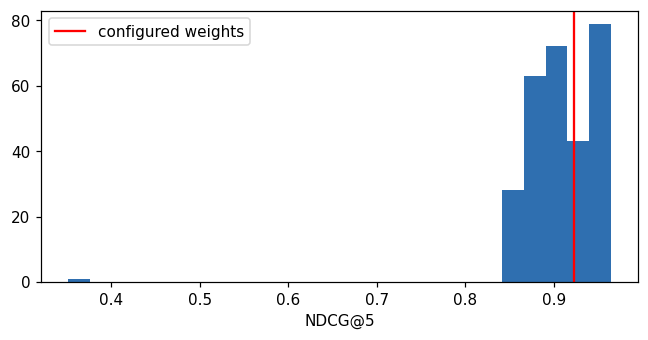

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.2)); ax.hist(sens['ndcg@5'], bins=25, color='#2f6fb0'); ax.axvline(chosen['ndcg@5'], color='r', label='configured weights'); ax.set_xlabel('NDCG@5'); ax.legend(); plt.tight_layout()

## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Evaluation on all 555 labelled pairs (ranking within each job's labelled pool).

In [12]:
per, agg = evaluate(ev2, 5); print({k: round(v, 3) for k, v in agg.items()})
print('success criteria check:', 'precision@5 >= 2x random:', agg['precision@5'] >= CFG['resume']['success_criteria']['precision_at_5_min_multiple_of_random'] * rb['precision@5'], '| hit rate >=', CFG['resume']['success_criteria']['hit_rate_at_5_min'], ':', agg['hit_rate@5'] >= CFG['resume']['success_criteria']['hit_rate_at_5_min'])

{'precision@5': 0.94, 'recall@5': 0.549, 'hit_rate@5': 1.0, 'ndcg@5': 0.923, 'mrr': 1.0, 'average_precision': 0.96, 'r_precision': 0.882}
success criteria check: precision@5 >= 2x random: True | hit rate >= 0.8 : True
